# Compact Mamba versus temporal CNN: matched participant evaluation

Two separate experiments on a common, checksum-verified cohort. **10 outer participant folds, inner-only random search, and three training seeds.** Both families get equal candidate budgets and identical splits. This is a follow-up experiment motivated by earlier development, not a new external confirmation.

**Mamba reference:** width 64, two blocks, state 16, convolution 16, expansion 2, mean/std pooling and dropout 0.2. **CNN reference:** width 32, four residual blocks with two kernel-7 convolutions each, dilations 1/2/4/8, channel LayerNorm, mean/std pooling and dropout 0.2. Its per-position receptive field is 181 samples before global pooling.

No duplicated validation samples, oversampling, augmentation, positional embeddings or additional Mamba MLP. Threshold is fixed at 0.5 (ties PD). Original ambiguous identities are quarantined before splits. All clinical analyses are post-evaluation, never model inputs.

Enable Kaggle Internet for verified source/data setup and a CUDA GPU for training. Outputs stay in RAM unless explicitly exported. The old width-128 notebook remains a separate baseline.

In [1]:
from pathlib import Path
import sys, subprocess, tempfile, json, copy, zipfile

SOURCE_REV = '1672baba2e60d7752b10e8cf50d8d7a22d205d94'
REPO_URL = 'https://github.com/AlexM3020/Subject-Independent-Evaluation-of-Mamba-for-Parkinson-s-Disease-Detection-from-Gait-Signals.git'
INSTALL_MAMBA = True  # Set True only if the backend is absent; restart kernel afterwards.
MAMBA_PACKAGE = 'mamba-ssm==2.3.2.post1'  # Explicit version; GPU check remains mandatory.
roots = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for b in roots for p in (b, b/'paper_repository') if (p/'gait/comparison.py').is_file()), None)
if REPO_ROOT is None:
    REPO_ROOT = Path(tempfile.gettempdir()) / ('gait-comparison-' + SOURCE_REV[:12])
    if not REPO_ROOT.exists():
        subprocess.run(['git','clone','--no-checkout',REPO_URL,str(REPO_ROOT)], check=True)
    subprocess.run(['git','-C',str(REPO_ROOT),'checkout','--detach',SOURCE_REV], check=True)
REPO_ROOT = REPO_ROOT.resolve()
SOURCE_FILES = ('models.py','cross_validation.py','comparison_models.py','comparison.py','official_data.py','diagnostics.py')
for name in SOURCE_FILES:
    expected = subprocess.run(['git','-C',str(REPO_ROOT),'show',SOURCE_REV+':gait/'+name], capture_output=True, check=True).stdout
    actual = (REPO_ROOT/'gait'/name).read_bytes()
    assert actual.replace(b'\r\n',b'\n') == expected.replace(b'\r\n',b'\n'), f'Changed pinned source: {name}'
sys.path.insert(0, str(REPO_ROOT))
if INSTALL_MAMBA:
    subprocess.run([sys.executable,'-m','pip','install',MAMBA_PACKAGE,'--no-build-isolation'], check=True)
print('Verified source:', SOURCE_REV)

Cloning into '/tmp/gait-comparison-1672baba2e60'...
HEAD is now at 1672bab Add matched Mamba CNN search, verified clinical audit and participant diagnostics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.4/216.4 kB 6.1 MB/s eta 0:00:00
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6/729.6 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.3/29.3 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.8/897.8 kB 30.7 MB/s eta 0:00:00
  Created wheel for mamba-ssm: filename=mamba_ssm-2.3.2.post1-cp312-cp312-linux_x86_64.whl size=

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cudf-cu12 26.2.1 requires numba-cuda[cu12]<0.23.0,>=0.22.2, but you hav

## Freeze the search budget before training
Default **8 candidates per family × 10 folds × 3 seeds = 480 fits** (up to 28,800 epochs before early stopping). This can exceed one free session. Use `MAX_NEW_TASKS` to stop cleanly after a completed family/seed/fold task and explicitly export progress. An interrupted task restarts; no automatic mid-epoch checkpoint saving.

The reference is included, then random search spans: windows 500/1,000/2,000; training versus recording normalization; max versus mean/std pooling; dropout 0–0.3; AdamW LR 2.5e-5–3e-4 and weight decay 1e-4–1e-2 (log-uniform). Mamba width 32/64/128, 1–2 blocks, state 16/32, convolution 8/16/32. CNN width 32/48/64, 3–4 blocks, kernel 5/7. Shared trial-index preprocessing/optimizer draws are matched.

A cheaper declared experiment is four candidates and one seed (80 fits). Do not change the budget after examining outer results. Training seeds change initialization/shuffling, not the participant folds. Search seed controls candidate generation; split seed controls the shared outer/inner partitions.

Common eligibility uses at least 2,000 samples regardless of selected context, preserving the previously curated cohort. Recording normalization is an **offline** complete-recording transform. Class weights use inner-training window counts only; participants with more windows still influence training more.

In [7]:
from dataclasses import asdict
from collections import Counter
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape
from gait import cross_validation as cv
from gait import comparison as cmp
from gait import official_data as official
from gait import diagnostics as diagnostics_module
assert Path(cmp.__file__).resolve().is_relative_to(REPO_ROOT), 'Restart kernel: stale gait imports'

CACHE_DIR = Path(tempfile.gettempdir()) / 'gaitpdb-1.0.0-verified-cache'
ALLOW_DOWNLOAD = True  # Input cache only; attached Kaggle data remain untouched.
TRAINING_SEEDS = (42, 123, 2026)
SEARCH_SEED = 90210
CANDIDATES_PER_FAMILY = 8
COMMON_MIN_SAMPLES = 2000
CFG = cv.Protocol(seq_len=1000, overlap=0.0, outer_folds=10, inner_fraction=0.2,
                  split_seed=42, training_seeds=TRAINING_SEEDS, batch_size=32,
                  max_epochs=60, patience=10, scheduler_patience=4, scheduler_factor=0.5,
                  min_lr=1e-7, bootstrap_samples=2000, bootstrap_seed=7301, num_workers=0)
CANDIDATES = cmp.sample_candidates(CANDIDATES_PER_FAMILY, SEARCH_SEED)
cmp.validate_search(CFG, CANDIDATES)
RUN_EXPERIMENT = False
MAX_NEW_TASKS = 2  # Two tasks = one outer fold, both families. None runs all remaining tasks.
results = globals().get('results', {})  # Never silently erase completed-fold progress.
PLAN = json.loads(json.dumps({'protocol':asdict(CFG),'candidates':CANDIDATES,
                             'search_seed':SEARCH_SEED,'common_min_samples':COMMON_MIN_SAMPLES}))
print(json.dumps(PLAN, indent=2))
print('Planned fits:', 2 * CFG.outer_folds * len(TRAINING_SEEDS) * CANDIDATES_PER_FAMILY)
print(cv.runtime_info())

def show_table(rows, columns=None, title='', limit=None):
    rows = list(rows)
    if title: print(title, '| rows:', len(rows))
    if not rows: print('No rows'); return
    columns = columns or list(dict.fromkeys(k for r in rows for k in r))
    def format_value(v):
        if v is None: return 'Unknown / not applicable'
        return f'{v:.4f}' if isinstance(v, float) else str(v)
    shown = rows if limit is None else rows[:limit]
    html = '<div style="max-height:480px;overflow:auto"><table><thead><tr>'
    html += ''.join('<th>'+escape(c)+'</th>' for c in columns) + '</tr></thead><tbody>'
    html += ''.join('<tr>'+''.join('<td>'+escape(format_value(r.get(c)))+'</td>' for c in columns)+'</tr>' for r in shown)
    display(HTML(html+'</tbody></table></div>'))
    if limit is not None and len(rows)>limit: print('Display limited; complete table remains in RAM and optional export.')

{
  "protocol": {
    "seq_len": 1000,
    "overlap": 0.0,
    "outer_folds": 10,
    "inner_fraction": 0.2,
    "split_seed": 42,
    "training_seeds": [
      42,
      123,
      2026
    ],
    "batch_size": 32,
    "max_epochs": 60,
    "patience": 10,
    "scheduler_patience": 4,
    "scheduler_factor": 0.5,
    "min_lr": 1e-07,
    "bootstrap_samples": 2000,
    "bootstrap_seed": 7301,
    "num_workers": 0
  },
  "candidates": {
    "mamba": [
      {
        "name": "mamba_00",
        "family": "mamba",
        "width": 64,
        "layers": 2,
        "state": 16,
        "kernel": 16,
        "dropout": 0.2,
        "pooling": "mean_std",
        "seq_len": 1000,
        "normalization": "training",
        "lr": 0.0001,
        "weight_decay": 0.001
      },
      {
        "name": "mamba_01",
        "family": "mamba",
        "width": 128,
        "layers": 2,
        "state": 16,
        "kernel": 16,
        "dropout": 0.3,
        "pooling": "mean_std",
        "seq_le

## Verify the full cohort and clinical sources
Pin the official manifest checksum, verify all 306 originals, then exclude **every recording** belonging to an identity implicated in cross-ID force duplicates. Known groups: GaPt17/GaPt18 and JuCo26/JuPt01; the second has conflicting diagnoses. Within-identity copies are counted once. No model performance informs exclusions.

Clinical TXT and HTML are independently checksum-verified and cross-checked by exact ID, study, diagnosis and HY. The TXT's later merged fields are not used. The malformed source ID `Juc010` is logged, not guessed. Missing/control HY is never inferred. Unknown clinical data do not remove a participant from model evaluation.

In [9]:
minimum = max(COMMON_MIN_SAMPLES, max(c['seq_len'] for cs in CANDIDATES.values() for c in cs))
records, audit, provenance = official.load_verified_cohort(CACHE_DIR, minimum, ALLOW_DOWNLOAD)
clinical, clinical_provenance = official.load_verified_clinical(CACHE_DIR, ALLOW_DOWNLOAD)
splits = cv.make_splits(records, CFG)
subject_labels = {r['subject']:r['label'] for r in records}
print('Curation:', provenance)
print('Audit statuses:', dict(Counter(r['status'] for r in audit)))
print('Participant counts:', dict(Counter(subject_labels.values())))
print('Retained recordings:', len(records))
print('Unmatched clinical IDs:', sorted(set(subject_labels)-set(clinical)))
print('Clinical source issues:', clinical_provenance['issues'])
for length in sorted({c['seq_len'] for cs in CANDIDATES.values() for c in cs}):
    print('Context',length,'samples ->',len(cv.make_windows(records,length,0)),'windows')
show_table([{'fold':s['fold'], **{part:dict(Counter(subject_labels[p] for p in s[part])) for part in ('train','validation','test')}} for s in splits], title='Shared fold assignments (0=Control, 1=PD)')
show_table([{'diagnosis':label,'hy_status':status,'n':n} for (label,status),n in Counter((subject_labels[s], clinical.get(s,{}).get('hy_status','unmatched')) for s in subject_labels).items()], title='Clinical coverage before training')
FROZEN_PLAN = copy.deepcopy(PLAN)

Curation: {'source': 'https://physionet.org/files/gaitpdb/1.0.0/', 'manifest_sha256': '44903ce52d5428ba218a9cdfd60d5646ab6674df4926233c756ae7c3c7cd50ec', 'min_samples': 2000, 'excluded_subjects': ['GaPt17', 'GaPt18', 'JuCo26', 'JuPt01'], 'conflict_groups': [['GaPt17_02.txt', 'GaPt18_01.txt'], ['JuCo26_01.txt', 'JuPt01_01.txt']], 'policy': 'exclude_all_recordings_of_cross_identity_duplicate_participants'}
Audit statuses: {'included': 292, 'participant_excluded_identity_ambiguity': 13, 'duplicate_excluded': 1}
Participant counts: {0: 71, 1: 90}
Retained recordings: 292
Unmatched clinical IDs: []
Clinical source issues: [{'raw_id': 'Juc010', 'reason': 'invalid_exact_id_or_short_row'}]
Context 500 samples -> 6296 windows
Context 1000 samples -> 3117 windows
Context 2000 samples -> 1529 windows
Shared fold assignments (0=Control, 1=PD) | rows: 10


fold,train,validation,test
1,"{0: 50, 1: 65}","{0: 13, 1: 16}","{0: 8, 1: 9}"
2,"{1: 65, 0: 51}","{1: 16, 0: 13}","{0: 7, 1: 9}"
3,"{0: 51, 1: 65}","{0: 13, 1: 16}","{0: 7, 1: 9}"
4,"{0: 51, 1: 65}","{0: 13, 1: 16}","{0: 7, 1: 9}"
5,"{0: 51, 1: 65}","{1: 16, 0: 13}","{0: 7, 1: 9}"
6,"{0: 51, 1: 65}","{0: 13, 1: 16}","{1: 9, 0: 7}"
7,"{0: 51, 1: 65}","{1: 16, 0: 13}","{0: 7, 1: 9}"
8,"{1: 65, 0: 51}","{1: 16, 0: 13}","{0: 7, 1: 9}"
9,"{0: 51, 1: 65}","{0: 13, 1: 16}","{0: 7, 1: 9}"
10,"{1: 65, 0: 51}","{1: 16, 0: 13}","{1: 9, 0: 7}"


Clinical coverage before training | rows: 3


diagnosis,hy_status,n
0,verified,18
1,verified,90
0,missing,53


## Actual backend check for every candidate
The check executes real forward/backward operations, preserving Mamba initialization and verifying finite gradients. It is not a training result. CNN is also tested on the same GPU. Listed receptive fields apply only to CNN features before pooling; Mamba has a recurrent temporal path, not a finite CNN receptive-field number.

The smoke batch is two; a training batch of 32 may require more memory. If training runs out of memory, start a new fixed plan with a smaller batch for **both** families; do not silently skip expensive candidates.

In [10]:
GPU_READY = False
if not torch.cuda.is_available():
    print('CUDA unavailable. Audit and diagnostics can run, but this experiment requires Kaggle CUDA.')
else:
    smoke_report = cmp.smoke_candidates(CANDIDATES, batch_size=2)
    show_table(smoke_report, title='Real model forward/backward checks passed')
    GPU_PLAN = copy.deepcopy(PLAN)
    GPU_READY = True

Real model forward/backward checks passed | rows: 16


family,candidate,parameters,receptive_field_samples
mamba,mamba_00,70210,Unknown / not applicable
mamba,mamba_01,242818,Unknown / not applicable
mamba,mamba_02,74178,Unknown / not applicable
mamba,mamba_03,22242,Unknown / not applicable
mamba,mamba_04,70210,Unknown / not applicable
mamba,mamba_05,21282,Unknown / not applicable
mamba,mamba_06,30498,Unknown / not applicable
mamba,mamba_07,70082,Unknown / not applicable
cnn,cnn_00,58914,181
cnn,cnn_01,166978,121


## Optional resume from an explicitly exported bundle
Leave the path empty for a fresh run. Upload your own previously exported ZIP as a Kaggle input to continue in a new session. Loading reads only JSON, not pickled models or executable code. Never merge results from different plans. Source, candidate list, cohort, runtime and completed-task consistency are checked when training resumes. Clinical metadata are reverified independently.

In [11]:
RESUME_ZIP = ''  # e.g. '/kaggle/input/my-run-progress/comparison_progress.zip'
if RESUME_ZIP:
    if results.get('runs'): raise RuntimeError('Results already in RAM; do not overwrite them')
    with zipfile.ZipFile(RESUME_ZIP) as archive:
        results = json.loads(archive.read('results.json'))
    print('Loaded completed tasks:',len(results.get('runs',[])),'| validated against the current plan at resume')
else:
    print('No progress bundle loaded.')

No progress bundle loaded.


## Run or continue the frozen experiment
The scheduler, stopping, checkpoint and hyperparameter selection use **inner participant log loss** only. Every family has its own winner; both are tested, and no family is selected from outer scores. The selected checkpoint is tested without refitting. Outer scores and error plots are withheld until all planned tasks finish.

A completed task contains all candidate histories, selected inner predictions, test windows/participants, normalizer, parameter counts, training times and peak GPU allocation. Progress prints one line per candidate, reducing output truncation. Times are workload measurements, not a controlled inference benchmark. No failed candidate is silently skipped.

In [19]:
RUN_EXPERIMENT=True
if RUN_EXPERIMENT:
    current = json.loads(json.dumps({'protocol':asdict(CFG),'candidates':CANDIDATES,
                                    'search_seed':SEARCH_SEED,'common_min_samples':COMMON_MIN_SAMPLES}))
    assert current == FROZEN_PLAN, 'Configuration changed after audit; freeze a new plan first'
    assert GPU_READY and GPU_PLAN == current, 'Run the GPU check for this exact plan first'
    cmp.run_comparison(records, audit, provenance, CFG, CANDIDATES, progress=results,
                       max_new_tasks=20, verbose=False)
    results['source_revision'] = SOURCE_REV
    results['search_seed'] = SEARCH_SEED
    results['clinical_provenance'] = clinical_provenance
    print('Completed tasks:',len(results['runs']),'of',2*CFG.outer_folds*len(CFG.training_seeds))
    print('Full experiment complete:',results['complete'])
else:
    print('Training disabled. Set RUN_EXPERIMENT=True after audit and GPU check. Results are preserved.')

Task 41/60: mamba, seed 2026, fold 1/10
  mamba_00: best inner NLL=0.6571, epoch=3, seconds=31
  mamba_01: best inner NLL=0.4925, epoch=6, seconds=77
  mamba_02: best inner NLL=0.6706, epoch=2, seconds=32
  mamba_03: best inner NLL=0.6419, epoch=14, seconds=38
  mamba_04: best inner NLL=0.4770, epoch=13, seconds=68
  mamba_05: best inner NLL=0.6174, epoch=10, seconds=29
  mamba_06: best inner NLL=0.4430, epoch=57, seconds=117
  mamba_07: best inner NLL=0.5226, epoch=13, seconds=56
Task 42/60: cnn, seed 2026, fold 1/10
  cnn_00: best inner NLL=0.7020, epoch=1, seconds=17
  cnn_01: best inner NLL=0.5191, epoch=1, seconds=29
  cnn_02: best inner NLL=0.6555, epoch=4, seconds=35
  cnn_03: best inner NLL=0.6452, epoch=1, seconds=15
  cnn_04: best inner NLL=0.5871, epoch=2, seconds=26
  cnn_05: best inner NLL=0.6330, epoch=1, seconds=23
  cnn_06: best inner NLL=0.4578, epoch=23, seconds=53
  cnn_07: best inner NLL=0.5322, epoch=9, seconds=48
Task 43/60: mamba, seed 2026, fold 2/10
  mamba_00:

## Explicit export (available between chunks)
Set `SAVE_RESULTS=True` only when you want to preserve completed tasks on disk. Each export gets a fresh timestamped filename; no overwrite, raw signals or automatic downloads. In-progress task weights are not saved. Before a session ends, export and download through Kaggle's file browser; RAM-only results do not survive a reset. This cell can be rerun after diagnostics to include all tables.

In [20]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    from datetime import datetime, timezone
    if not results.get('runs'): raise RuntimeError('No completed task available')
    results['source_revision'] = SOURCE_REV
    results['search_seed'] = SEARCH_SEED
    results['clinical_provenance'] = clinical_provenance
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    export_path = Path('/kaggle/working') / f'comparison_progress_{stamp}.zip'
    print('Saved:',cv.export_results(results,export_path))
else:
    print('No result files written. Progress remains in RAM.')

Saved: /kaggle/working/comparison_progress_20261116T204946297832Z.zip


## Complete OOF metrics and paired comparison
Each eligible participant is tested exactly once per model/seed. Pooled metrics are primary, not an unweighted average of unequal fold sizes. Individual bootstrap intervals resample participants within diagnosis, conditional on fitted OOF predictions and class counts; they exclude refitting and new-split uncertainty. Fold SD is not a CI. Repeated seed rows are never treated as independent extra people.

Paired differences resample the same participants for both families and every seed, then average the seed-specific metric differences. This is **not** a prediction ensemble. Intervals are descriptive and conditional, not proof of external superiority. Do not select the best seed.

In [21]:
if not results.get('complete'):
    print('Finish all planned tasks before inspecting outer results.')
else:
    diagnostics = diagnostics_module.build_diagnostics(results, clinical)
    results['diagnostics'] = diagnostics
    results['clinical_provenance'] = clinical_provenance
    metric_rows = []
    for family, summaries in results['summaries'].items():
        for seed, summary in summaries.items():
            for name, interval in summary['confidence_intervals'].items():
                metric_rows.append({'family':family,'seed':seed,'metric':name,**interval})
    show_table(metric_rows, title='Participant OOF metrics and 95% bootstrap intervals')
    show_table([{'family':f,'seed':s,**v['participant_metrics'],'fold_accuracy_sd':v['fold_accuracy_std']} for f,ss in results['summaries'].items() for s,v in ss.items()], title='Counts, log loss and fold SD')
    show_table([{'family':f,'seed':s,**v['window_metrics']} for f,ss in results['summaries'].items() for s,v in ss.items()], title='Secondary pooled window metrics')
    across = []
    for family, summaries in results['summaries'].items():
        for metric in ('accuracy','balanced_accuracy','macro_f1','sensitivity','specificity','roc_auc'):
            values = [s['participant_metrics'][metric] for s in summaries.values()]
            across.append({'family':family,'metric':metric,'seed_mean':float(np.mean(values)),
                           'seed_sample_sd':float(np.std(values,ddof=1)) if len(values)>1 else None,'n_seeds':len(values)})
    show_table(across, title='Training-seed variability on the same folds')
    show_table(diagnostics['paired_comparison'], title='Paired Mamba minus CNN differences: seed-averaged metrics')

Participant OOF metrics and 95% bootstrap intervals | rows: 36


family,seed,metric,estimate,lower,upper
cnn,42,accuracy,0.7453,0.6770,0.8137
cnn,42,balanced_accuracy,0.7425,0.6735,0.8107
cnn,42,macro_f1,0.7421,0.6725,0.8105
cnn,42,sensitivity,0.7667,0.6778,0.8447
cnn,42,specificity,0.7183,0.6056,0.8169
cnn,42,roc_auc,0.8049,0.7343,0.8700
cnn,123,accuracy,0.7702,0.7081,0.8323
cnn,123,balanced_accuracy,0.7677,0.7028,0.8336
cnn,123,macro_f1,0.7673,0.7025,0.8310
cnn,123,sensitivity,0.7889,0.7000,0.8667


Counts, log loss and fold SD | rows: 6


family,seed,accuracy,balanced_accuracy,macro_f1,sensitivity,specificity,roc_auc,log_loss,tn,fp,fn,tp,n,fold_accuracy_sd
cnn,42,0.7453,0.7425,0.7421,0.7667,0.7183,0.8049,0.5735,51,20,21,69,161,0.0859
cnn,123,0.7702,0.7677,0.7673,0.7889,0.7465,0.8357,0.5734,53,18,19,71,161,0.1070
cnn,2026,0.7640,0.7636,0.7619,0.7667,0.7606,0.8315,0.5327,54,17,21,69,161,0.0873
mamba,42,0.7205,0.7232,0.7194,0.7000,0.7465,0.8247,0.5461,53,18,27,63,161,0.0967
mamba,123,0.7329,0.7314,0.7303,0.7444,0.7183,0.8047,0.5788,51,20,23,67,161,0.0523
mamba,2026,0.7516,0.7495,0.7488,0.7667,0.7324,0.8308,0.5315,52,19,21,69,161,0.0966


Secondary pooled window metrics | rows: 6


family,seed,accuracy,balanced_accuracy,macro_f1,sensitivity,specificity,roc_auc,log_loss,tn,fp,fn,tp,n
cnn,42,0.7396,0.7177,0.7101,0.7785,0.6570,0.7881,0.6109,862,450,617,2168,4097
cnn,123,0.7818,0.7756,0.7599,0.7926,0.7587,0.8214,0.8251,1138,362,674,2575,4749
cnn,2026,0.7443,0.7449,0.7278,0.7430,0.7468,0.7977,0.6353,926,314,636,1839,3715
mamba,42,0.7530,0.7495,0.7336,0.7597,0.7393,0.8247,0.6245,1171,413,784,2478,4846
mamba,123,0.7549,0.7495,0.7315,0.7640,0.7351,0.8012,0.5777,952,343,672,2175,4142
mamba,2026,0.7761,0.7630,0.7497,0.7974,0.7286,0.8298,0.5159,988,368,612,2409,4377


Training-seed variability on the same folds | rows: 12


family,metric,seed_mean,seed_sample_sd,n_seeds
cnn,accuracy,0.7598,0.0129,3
cnn,balanced_accuracy,0.7579,0.0135,3
cnn,macro_f1,0.7571,0.0133,3
cnn,sensitivity,0.7741,0.0128,3
cnn,specificity,0.7418,0.0215,3
cnn,roc_auc,0.8240,0.0167,3
mamba,accuracy,0.7350,0.0156,3
mamba,balanced_accuracy,0.7347,0.0135,3
mamba,macro_f1,0.7328,0.0148,3
mamba,sensitivity,0.7370,0.0339,3


Paired Mamba minus CNN differences: seed-averaged metrics | rows: 6


metric,mamba_minus_cnn,lower,upper,n_participants,n_seeds
accuracy,-0.0248,-0.0559,0.0083,161,3
balanced_accuracy,-0.0232,-0.0540,0.0107,161,3
macro_f1,-0.0243,-0.0557,0.0096,161,3
sensitivity,-0.0370,-0.0815,0.0074,161,3
specificity,-0.0094,-0.0516,0.0376,161,3
roc_auc,-0.0039,-0.0314,0.0254,161,3


## Participant errors, cohort patterns and clinical severity
These are exploratory descriptions, not causal explanations. Study/diagnosis and HY tables include their actual sample sizes. Only verified metadata determine HY; absent or conflicting values stay Unknown. Control HY=0 is never inferred. A single-class subgroup has no defined ROC-AUC. Wilson intervals for subgroup correctness are pointwise, not multiplicity-adjusted confirmatory comparisons.

PD stage sensitivity counts correctly detected PD participants at each stage; it is not severity-classification accuracy. Small stage/study cells can be highly uncertain. `confident_error` means wrong predicted class with probability at least 0.8; probabilities are not assumed calibrated. All errors remain inspectable, not only confident ones.

Inner-validation high-loss rows come from selected checkpoints and may repeat a person across folds; do not combine them as independent people or confuse them with outer tests. Their individual NLL contributions can explain why a small number of errors affect validation curves.

In [22]:
if results.get('complete') and 'diagnostics' in results:
    diagnostics = results['diagnostics']
    show_table(diagnostics['participant_errors'], ['family','seed','fold','subject','study','diagnosis','probability','prediction','correct','recordings','windows','hy','hy_status','age','confidence','nll'], title='Complete participant-level outer error table')
    show_table(diagnostics['by_study'], title='Outer results by contributing study')
    show_table(diagnostics['by_study_diagnosis'], title='Outer results by study and diagnosis')
    show_table(diagnostics['by_fold'], title='Outer results by fold')
    show_table(diagnostics['pd_severity'], title='PD sensitivity by verified Hoehn–Yahr stage (including unknown/absent)')
    show_table(diagnostics['pd_severity_study'], title='PD sensitivity by study and stage')
    show_table(diagnostics['metadata_coverage'], title='Metadata coverage and unresolved joins')
    show_table(diagnostics['confidently_wrong'], title='Confidently wrong outer participants, ranked by NLL')
    show_table(sorted(diagnostics['participant_errors'], key=lambda r:-r['nll']), title='All outer participants ranked by individual NLL', limit=30)
    show_table(diagnostics['inner_high_loss'], title='Selected inner-validation checkpoint NLL contributors (not independent across folds)', limit=30)
    show_table(sorted(diagnostics['seed_stability'], key=lambda r:(-r['error_seeds'],r['family'],r['subject'])), title='Participant consistency across training seeds')
else:
    print('Run the complete-result metrics cell first.')

Complete participant-level outer error table | rows: 966


family,seed,fold,subject,study,diagnosis,probability,prediction,correct,recordings,windows,hy,hy_status,age,confidence,nll
mamba,42,1,GaCo02,Ga,Control,0.0000,0,True,2,48,0.0000,verified,74.0000,1.0000,0.0000
mamba,42,1,GaCo04,Ga,Control,0.6940,1,False,2,48,0.0000,verified,86.0000,0.6940,1.1841
mamba,42,1,GaCo14,Ga,Control,0.0322,0,True,3,72,0.0000,verified,68.0000,0.9678,0.0327
mamba,42,1,GaPt09,Ga,PD,0.9988,1,True,2,48,3.0000,verified,69.0000,0.9988,0.0012
mamba,42,1,GaPt13,Ga,PD,0.9725,1,True,3,72,2.0000,verified,70.0000,0.9725,0.0279
mamba,42,1,GaPt25,Ga,PD,0.0400,0,False,3,72,2.5000,verified,81.0000,0.9600,3.2181
mamba,42,1,JuCo07,Ju,Control,0.0002,0,True,1,16,Unknown / not applicable,missing,62.0000,0.9998,0.0002
mamba,42,1,JuCo20,Ju,Control,0.9209,1,False,1,21,Unknown / not applicable,missing,67.0000,0.9209,2.5373
mamba,42,1,JuCo25,Ju,Control,0.0000,0,True,1,16,Unknown / not applicable,missing,53.0000,1.0000,0.0000
mamba,42,1,JuPt10,Ju,PD,0.9587,1,True,7,128,3.0000,verified,69.0000,0.9587,0.0422


Outer results by contributing study | rows: 18


family,seed,study,n,correct,errors,accuracy,accuracy_wilson_lower,accuracy_wilson_upper,mean_nll,mean_pd_probability,sensitivity,specificity,roc_auc,balanced_accuracy
cnn,123,Ga,45,38,7,0.8444,0.7122,0.9225,0.5593,0.6030,0.9259,0.7222,0.8868,0.8241
cnn,123,Ju,52,40,12,0.7692,0.6387,0.8628,0.5499,0.5049,0.7857,0.7500,0.8363,0.7679
cnn,123,Si,64,46,18,0.7188,0.5987,0.8141,0.6023,0.4744,0.6857,0.7586,0.8039,0.7222
cnn,2026,Ga,45,33,12,0.7333,0.5896,0.8404,0.6777,0.6034,0.7778,0.6667,0.7695,0.7222
cnn,2026,Ju,52,41,11,0.7885,0.6597,0.8776,0.3910,0.5486,0.8214,0.7500,0.8988,0.7857
cnn,2026,Si,64,49,15,0.7656,0.6487,0.8525,0.5459,0.4621,0.7143,0.8276,0.8414,0.7709
cnn,42,Ga,45,33,12,0.7333,0.5896,0.8404,0.5949,0.6506,0.8519,0.5556,0.8045,0.7037
cnn,42,Ju,52,40,12,0.7692,0.6387,0.8628,0.5124,0.5535,0.7857,0.7500,0.8318,0.7679
cnn,42,Si,64,47,17,0.7344,0.6152,0.8270,0.6080,0.5082,0.6857,0.7931,0.7852,0.7394
mamba,123,Ga,45,35,10,0.7778,0.6373,0.8746,0.4784,0.6226,0.8519,0.6667,0.8498,0.7593


Outer results by study and diagnosis | rows: 36


family,seed,study,diagnosis,n,correct,errors,accuracy,accuracy_wilson_lower,accuracy_wilson_upper,mean_nll,mean_pd_probability,sensitivity,specificity,roc_auc,balanced_accuracy
cnn,123,Ga,Control,18,13,5,0.7222,0.4913,0.8750,0.9799,0.3083,Unknown / not applicable,0.7222,Unknown / not applicable,Unknown / not applicable
cnn,123,Ga,PD,27,25,2,0.9259,0.7663,0.9794,0.2790,0.7994,0.9259,Unknown / not applicable,Unknown / not applicable,Unknown / not applicable
cnn,123,Ju,Control,24,18,6,0.7500,0.5510,0.8800,0.4872,0.2783,Unknown / not applicable,0.7500,Unknown / not applicable,Unknown / not applicable
cnn,123,Ju,PD,28,22,6,0.7857,0.6046,0.8979,0.6037,0.6991,0.7857,Unknown / not applicable,Unknown / not applicable,Unknown / not applicable
cnn,123,Si,Control,29,22,7,0.7586,0.5789,0.8778,0.5269,0.2764,Unknown / not applicable,0.7586,Unknown / not applicable,Unknown / not applicable
cnn,123,Si,PD,35,24,11,0.6857,0.5202,0.8145,0.6648,0.6385,0.6857,Unknown / not applicable,Unknown / not applicable,Unknown / not applicable
cnn,2026,Ga,Control,18,12,6,0.6667,0.4375,0.8372,0.8741,0.3805,Unknown / not applicable,0.6667,Unknown / not applicable,Unknown / not applicable
cnn,2026,Ga,PD,27,21,6,0.7778,0.5924,0.8939,0.5468,0.7520,0.7778,Unknown / not applicable,Unknown / not applicable,Unknown / not applicable
cnn,2026,Ju,Control,24,18,6,0.7500,0.5510,0.8800,0.4945,0.2916,Unknown / not applicable,0.7500,Unknown / not applicable,Unknown / not applicable
cnn,2026,Ju,PD,28,23,5,0.8214,0.6441,0.9212,0.3022,0.7688,0.8214,Unknown / not applicable,Unknown / not applicable,Unknown / not applicable


... (12 outputs left out)

Display limited; complete table remains in RAM and optional export.
Selected inner-validation checkpoint NLL contributors (not independent across folds) | rows: 1740


family,seed,fold,partition,subject,study,label,diagnosis,probability,prediction,correct,recordings,windows,hy,hy_status,age,confidence,confident_error,nll,candidate
mamba,123,6,validation,GaCo07,Ga,0,Control,0.9906,1,False,2,24,0.0000,verified,79.0000,0.9906,True,4.6619,mamba_00
mamba,123,6,validation,SiCo17,Si,0,Control,0.9778,1,False,1,12,Unknown / not applicable,missing,64.0000,0.9778,True,3.8067,mamba_00
mamba,123,7,validation,SiCo16,Si,0,Control,0.9764,1,False,1,6,Unknown / not applicable,missing,60.0000,0.9764,True,3.7467,mamba_04
cnn,2026,10,validation,JuCo12,Ju,0,Control,0.9763,1,False,1,19,Unknown / not applicable,missing,72.0000,0.9763,True,3.7409,cnn_07
cnn,42,4,validation,SiCo28,Si,0,Control,0.9738,1,False,1,12,Unknown / not applicable,missing,61.0000,0.9738,True,3.6423,cnn_06
cnn,2026,1,validation,SiCo17,Si,0,Control,0.9737,1,False,1,12,Unknown / not applicable,missing,64.0000,0.9737,True,3.6396,cnn_06
mamba,42,1,validation,SiPt30,Si,1,PD,0.0266,0,False,1,24,2.0000,verified,60.0000,0.9734,True,3.6287,mamba_01
cnn,123,4,validation,SiCo28,Si,0,Control,0.9711,1,False,1,12,Unknown / not applicable,missing,61.0000,0.9711,True,3.5452,cnn_06
mamba,2026,3,validation,SiPt35,Si,1,PD,0.0302,0,False,1,24,2.0000,verified,57.0000,0.9698,True,3.4998,mamba_07
cnn,42,5,validation,SiCo28,Si,0,Control,0.9682,1,False,1,12,Unknown / not applicable,missing,61.0000,0.9682,True,3.4470,cnn_06


Display limited; complete table remains in RAM and optional export.
Participant consistency across training seeds | rows: 322


family,subject,study,label,hy,hy_status,fold,n_seeds,correct_seeds,error_seeds,always_wrong,predictions_disagree,probability_mean,probability_std,probability_min,probability_max
cnn,GaCo01,Ga,0,0.0000,verified,4,3,0,3,True,False,0.8767,0.0615,0.8146,0.9376
cnn,GaCo04,Ga,0,0.0000,verified,1,3,0,3,True,False,0.8274,0.1228,0.6922,0.9321
cnn,GaCo06,Ga,0,0.0000,verified,3,3,0,3,True,False,0.8923,0.1307,0.7469,1.0000
cnn,GaCo07,Ga,0,0.0000,verified,2,3,0,3,True,False,0.8413,0.2353,0.5697,0.9813
cnn,GaCo08,Ga,0,0.0000,verified,5,3,0,3,True,False,0.5678,0.0084,0.5589,0.5754
cnn,GaPt06,Ga,1,2.0000,verified,7,3,0,3,True,False,0.1153,0.0925,0.0235,0.2085
cnn,GaPt27,Ga,1,2.0000,verified,9,3,0,3,True,False,0.3110,0.1316,0.2252,0.4625
cnn,JuCo11,Ju,0,Unknown / not applicable,missing,7,3,0,3,True,False,0.8309,0.0488,0.7848,0.8821
cnn,JuCo12,Ju,0,Unknown / not applicable,missing,7,3,0,3,True,False,0.8657,0.0533,0.8106,0.9170
cnn,JuCo20,Ju,0,Unknown / not applicable,missing,1,3,0,3,True,False,0.9033,0.0189,0.8902,0.9249


In [23]:
if results.get('complete'):
    selection_rows, trial_rows = [], []
    for r in results['runs']:
        selected = r['trials'][r['selected_candidate']]
        selection_rows.append({'family':r['family'],'seed':r['seed'],'fold':r['fold'],**selected['candidate'],
                               'best_epoch':selected['best_epoch'],'parameters':selected['parameters'],
                               'inner_nll':selected['inner_metrics']['log_loss']})
        for i,t in enumerate(r['trials']):
            trial_rows.append({'family':r['family'],'seed':r['seed'],'fold':r['fold'],**t['candidate'],
                               'selected':i==r['selected_candidate'],'best_epoch':t['best_epoch'],
                               'inner_nll':t['inner_metrics']['log_loss'],'parameters':t['parameters'],
                               'training_seconds':t['seconds'],'peak_allocated_bytes':t['peak_allocated_bytes'],
                               'receptive_field_samples':t['receptive_field_samples']})
    results['selection_table'] = selection_rows
    results['trial_table'] = trial_rows
    show_table(selection_rows, title='Selected settings in every model/seed/fold')
    show_table(trial_rows, title='All search trials and measured resource use', limit=40)
    print('Total candidate-training hours:',sum(r['training_seconds'] for r in trial_rows)/3600)

Selected settings in every model/seed/fold | rows: 60


family,seed,fold,name,width,layers,state,kernel,dropout,pooling,seq_len,normalization,lr,weight_decay,best_epoch,parameters,inner_nll
mamba,42,1,mamba_01,128,2,16,16,0.3000,mean_std,500,recording,0.0003,0.0011,8,242818,0.5003
cnn,42,1,cnn_07,48,4,Unknown / not applicable,7,0.2000,max,500,recording,0.0000,0.0027,10,131282,0.5181
mamba,42,2,mamba_03,32,2,16,16,0.1000,max,2000,training,0.0002,0.0010,60,22242,0.4473
cnn,42,2,cnn_00,32,4,Unknown / not applicable,7,0.2000,mean_std,1000,training,0.0001,0.0010,6,58914,0.4197
mamba,42,3,mamba_03,32,2,16,16,0.1000,max,2000,training,0.0002,0.0010,34,22242,0.2616
cnn,42,3,cnn_05,32,4,Unknown / not applicable,5,0.2000,mean_std,500,training,0.0000,0.0019,11,42530,0.3515
mamba,42,4,mamba_07,64,2,16,16,0.2000,max,500,recording,0.0000,0.0027,19,70082,0.4142
cnn,42,4,cnn_06,32,4,Unknown / not applicable,7,0.1000,mean_std,1000,recording,0.0000,0.0014,16,58914,0.4247
mamba,42,5,mamba_07,64,2,16,16,0.2000,max,500,recording,0.0000,0.0027,6,70082,0.5688
cnn,42,5,cnn_06,32,4,Unknown / not applicable,7,0.1000,mean_std,1000,recording,0.0000,0.0014,25,58914,0.5584


All search trials and measured resource use | rows: 480


family,seed,fold,name,width,layers,state,kernel,dropout,pooling,seq_len,normalization,lr,weight_decay,selected,best_epoch,inner_nll,parameters,training_seconds,peak_allocated_bytes,receptive_field_samples
mamba,42,1,mamba_00,64,2,16,16,0.2000,mean_std,1000,training,0.0001,0.0010,False,4,0.6694,70210,32.7695,421209088,Unknown / not applicable
mamba,42,1,mamba_01,128,2,16,16,0.3000,mean_std,500,recording,0.0003,0.0011,True,8,0.5003,242818,84.3364,412915200,Unknown / not applicable
mamba,42,1,mamba_02,64,2,16,32,0.1000,max,500,training,0.0000,0.0026,False,6,0.6793,74178,41.2773,220346368,Unknown / not applicable
mamba,42,1,mamba_03,32,2,16,16,0.1000,max,2000,training,0.0002,0.0010,False,16,0.6770,22242,40.1784,444426240,Unknown / not applicable
mamba,42,1,mamba_04,64,2,16,16,0.2000,mean_std,2000,recording,0.0002,0.0002,False,28,0.5758,70210,110.9577,819355648,Unknown / not applicable
mamba,42,1,mamba_05,32,2,16,8,0.2000,mean_std,500,training,0.0000,0.0019,False,4,0.6688,21282,20.2930,126157824,Unknown / not applicable
mamba,42,1,mamba_06,32,2,32,32,0.1000,mean_std,1000,recording,0.0000,0.0014,False,1,0.6874,30498,20.9989,251895808,Unknown / not applicable
mamba,42,1,mamba_07,64,2,16,16,0.2000,max,500,recording,0.0000,0.0027,False,18,0.5530,70082,67.3440,219527168,Unknown / not applicable
cnn,42,1,cnn_00,32,4,Unknown / not applicable,7,0.2000,mean_std,1000,training,0.0001,0.0010,False,1,0.7439,58914,16.7795,148798464,181
cnn,42,1,cnn_01,64,4,Unknown / not applicable,5,0.3000,mean_std,500,recording,0.0003,0.0011,False,10,0.6873,166978,53.0059,148063232,121


Display limited; complete table remains in RAM and optional export.
Total candidate-training hours: 5.995673690623332


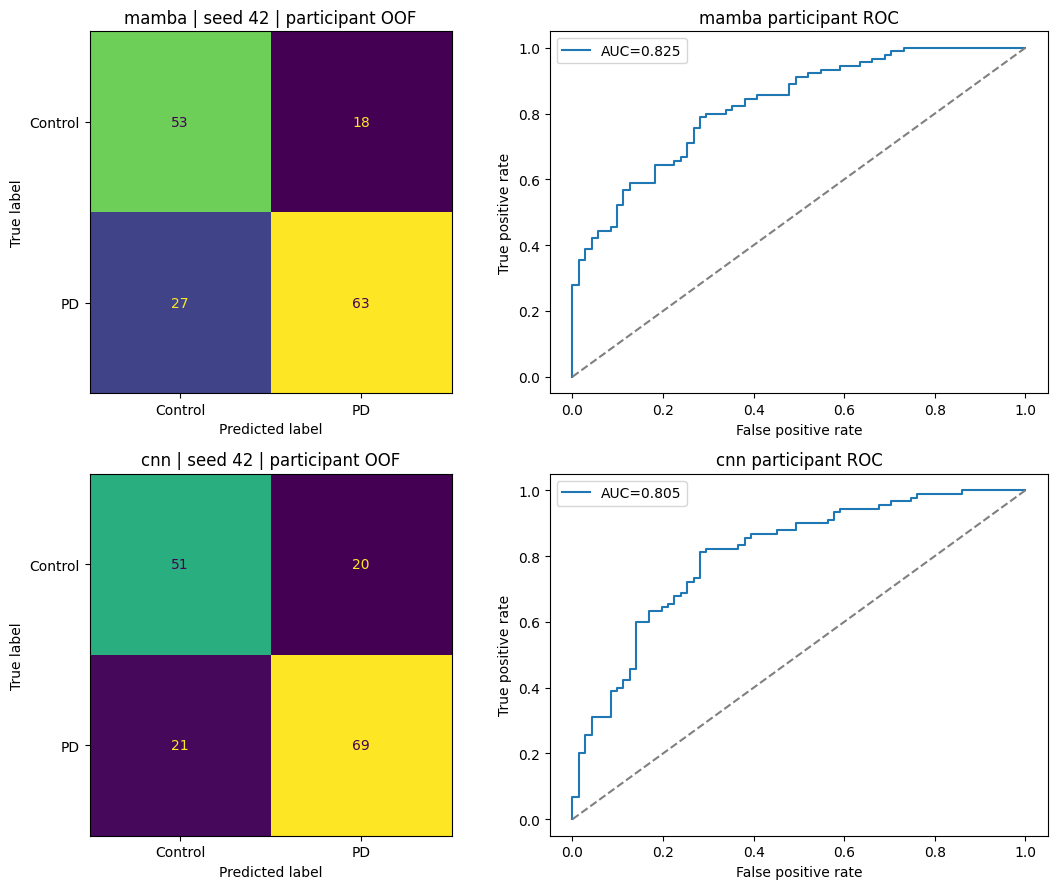

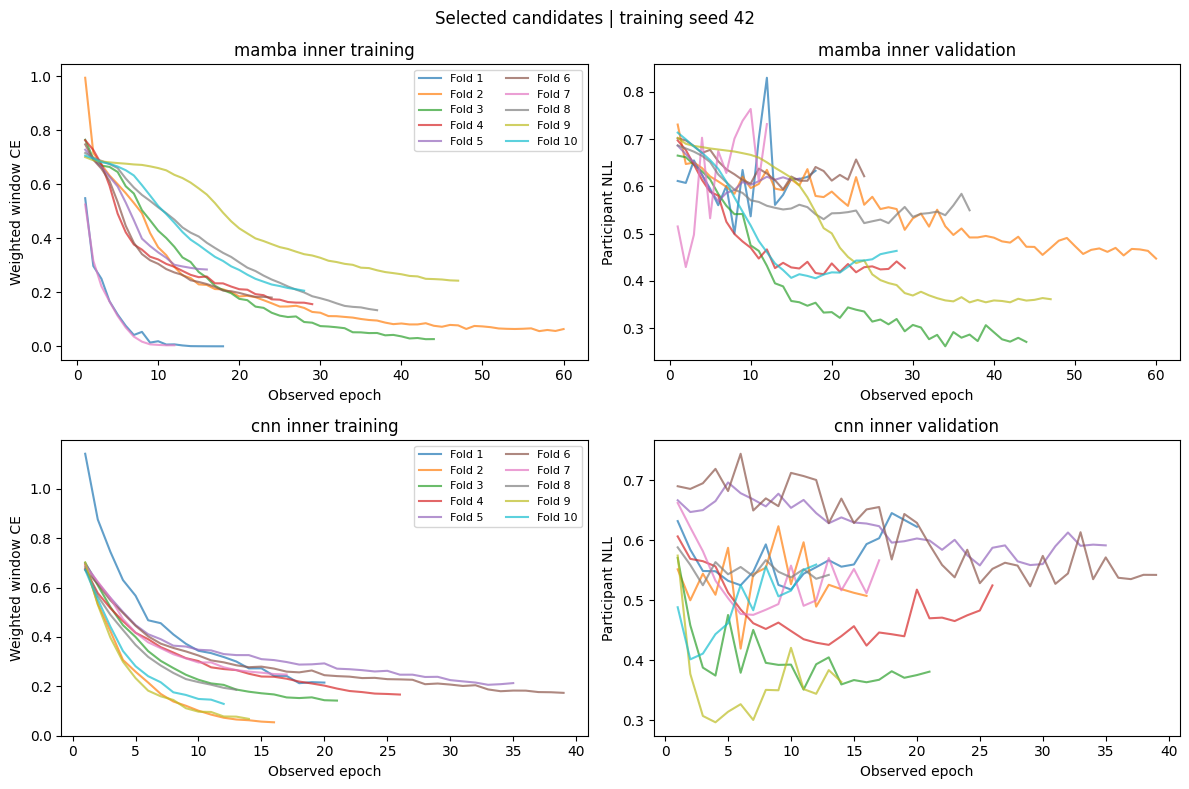

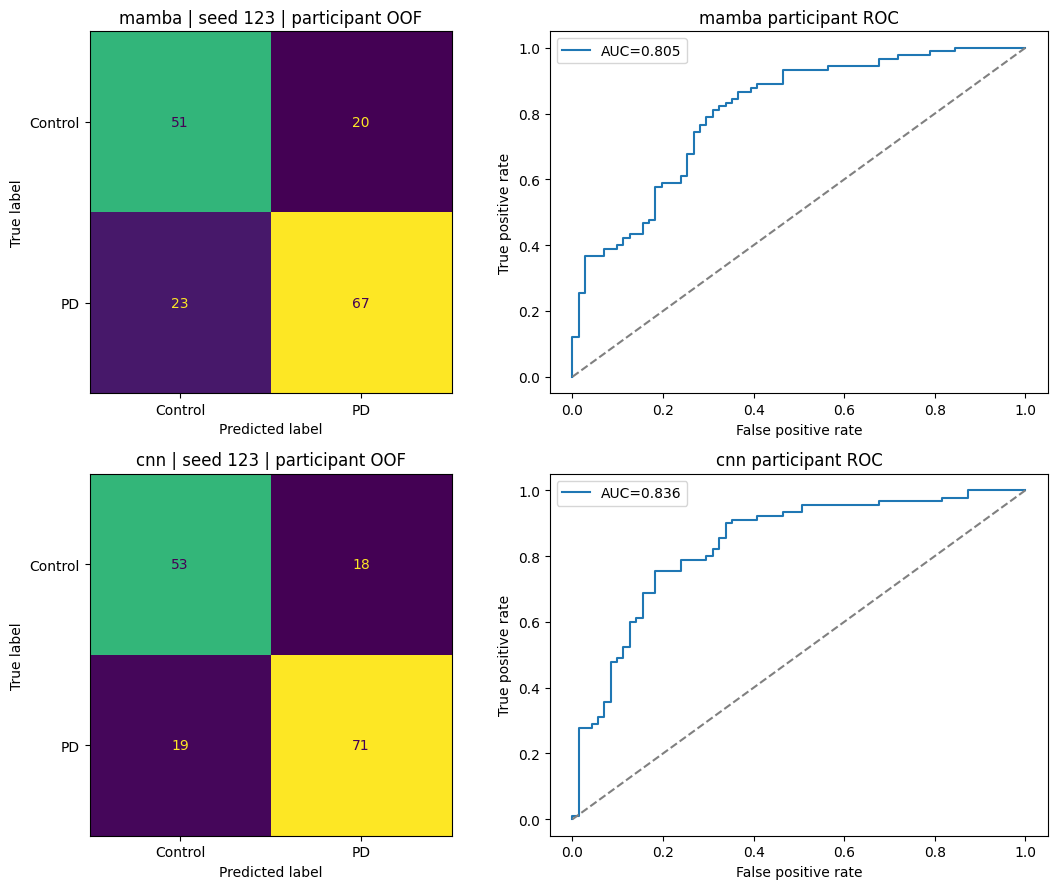

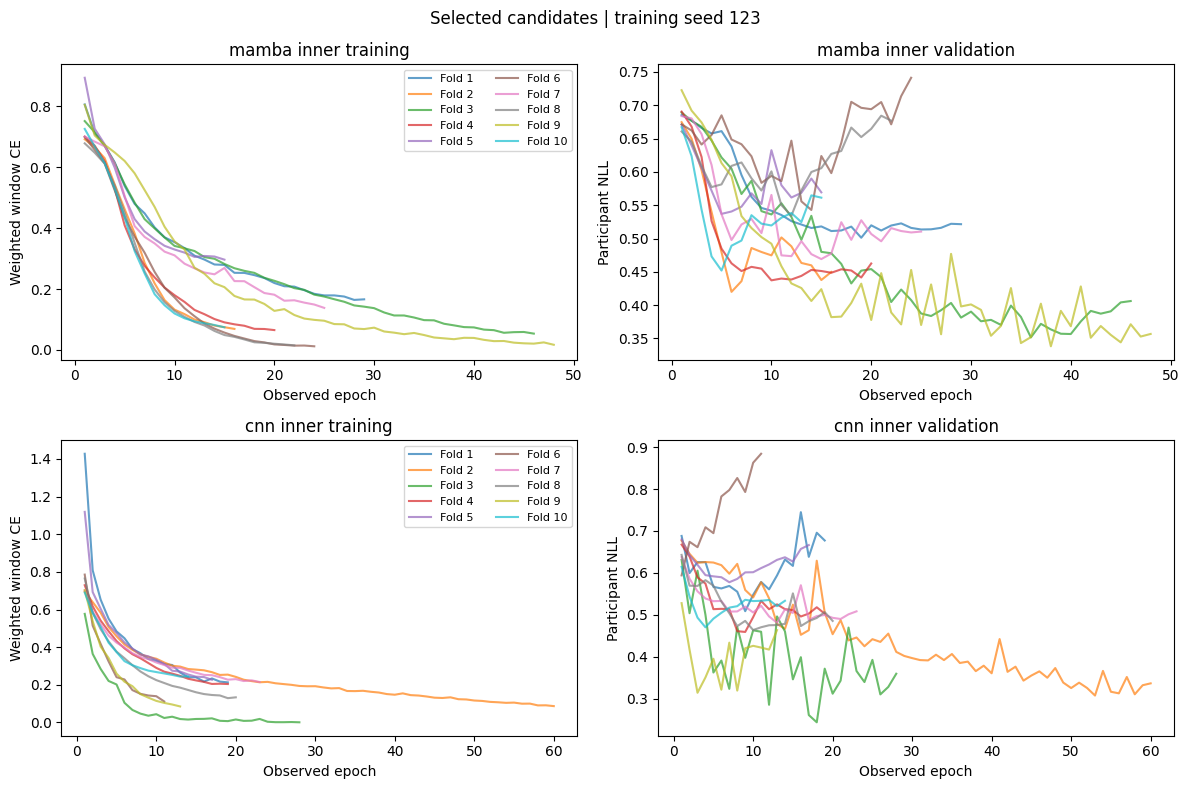

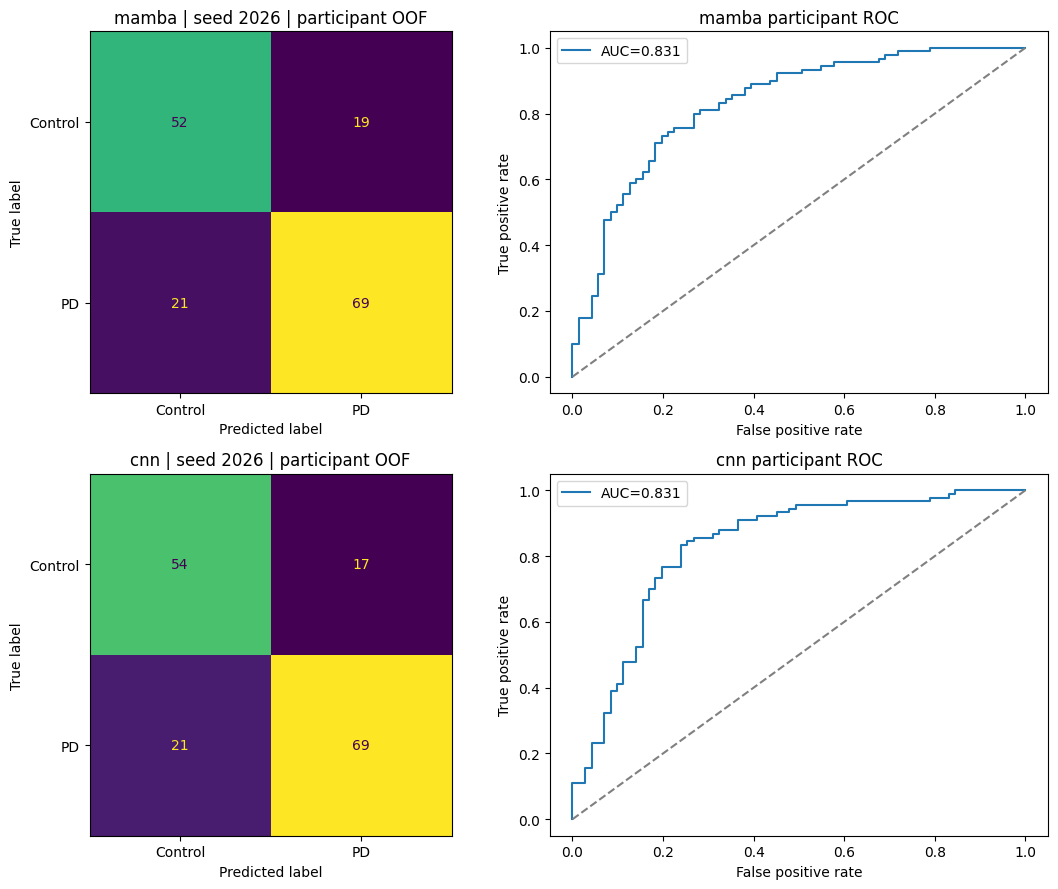

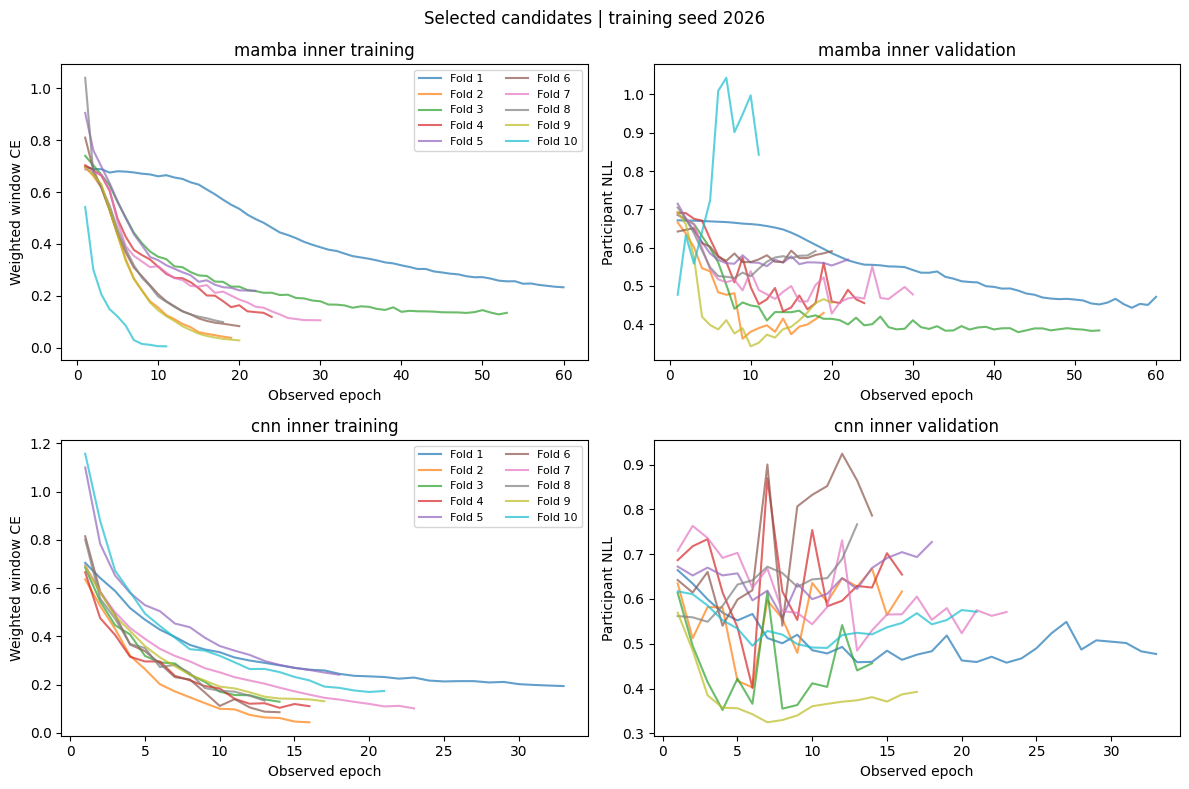

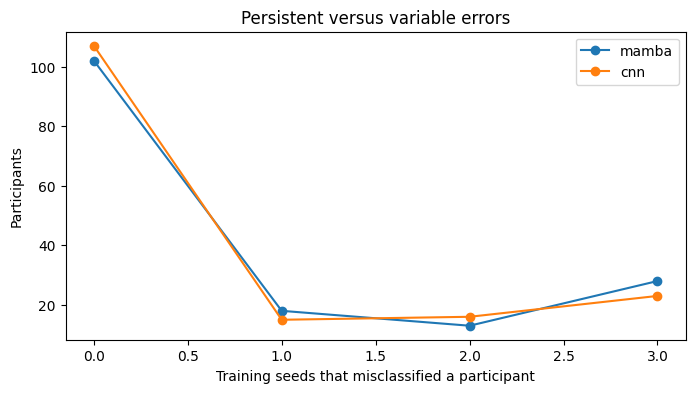

In [24]:
# Display only; no plot files, interpolated histories, or artificial epoch padding.
if results.get('complete'):
    from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, roc_auc_score
    for seed in results['protocol']['training_seeds']:
        fig, axes = plt.subplots(2, 2, figsize=(11, 9))
        for index,family in enumerate(('mamba','cnn')):
            rows = [p for r in results['runs'] if r['family']==family and r['seed']==seed for p in r['test_participants']]
            y = np.array([p['label'] for p in rows]); p = np.array([p['probability'] for p in rows])
            ConfusionMatrixDisplay(confusion_matrix(y,p>=.5,labels=[0,1]),display_labels=['Control','PD']).plot(ax=axes[index,0],colorbar=False)
            axes[index,0].set_title(f'{family} | seed {seed} | participant OOF')
            fpr,tpr,_ = roc_curve(y,p)
            axes[index,1].plot(fpr,tpr,label=f'AUC={roc_auc_score(y,p):.3f}')
            axes[index,1].plot([0,1],[0,1],'--',color='gray'); axes[index,1].legend()
            axes[index,1].set(xlabel='False positive rate',ylabel='True positive rate',title=family+' participant ROC')
        fig.tight_layout(); plt.show()
        fig, axes = plt.subplots(2,2,figsize=(12,8))
        for index,family in enumerate(('mamba','cnn')):
            for r in results['runs']:
                if r['family']!=family or r['seed']!=seed: continue
                history=r['trials'][r['selected_candidate']]['history']
                epochs=[h['epoch'] for h in history]
                axes[index,0].plot(epochs,[h['train_loss'] for h in history],alpha=.7,label=f"Fold {r['fold']}")
                axes[index,1].plot(epochs,[h['validation_log_loss'] for h in history],alpha=.7)
            axes[index,0].set(title=family+' inner training',xlabel='Observed epoch',ylabel='Weighted window CE')
            axes[index,1].set(title=family+' inner validation',xlabel='Observed epoch',ylabel='Participant NLL')
            axes[index,0].legend(ncol=2,fontsize=8)
        fig.suptitle(f'Selected candidates | training seed {seed}'); fig.tight_layout(); plt.show()
    if 'diagnostics' in results:
        stability=results['diagnostics']['seed_stability']
        fig,ax=plt.subplots(figsize=(8,4))
        for family in ('mamba','cnn'):
            counts=Counter(r['error_seeds'] for r in stability if r['family']==family)
            x=np.arange(len(results['protocol']['training_seeds'])+1)
            ax.plot(x,[counts.get(int(i),0) for i in x],marker='o',label=family)
        ax.set(xlabel='Training seeds that misclassified a participant',ylabel='Participants',title='Persistent versus variable errors')
        ax.legend(); plt.show()

## Preserve and interpret the result
Rerun the explicit export cell after diagnostics to include the full tables. Report both models, all declared seeds, the search budget, actual cohort exclusions and source/environment provenance. Do not present post-hoc HY/study patterns as validated biomarkers, or conditional bootstrap intervals as uncertainty across hospitals or refitted datasets.

If follow-up changes are motivated by these outer errors, label them exploratory and predeclare the next experiment. More inner candidates can overfit a 29-person inner holdout; full inner cross-validation and external validation are higher-cost extensions.